# Building the matrices

This tutorial introduces the two test systems in COBWEB and the one thing every system has to hand to the rest of the code: a Hamiltonian matrix, with a label saying what each row means. It takes about 25 minutes.

Run `make hamiltonians` from the repo root before starting. On Google Colab the setup cell below clones the repo and runs it for you.

In [ ]:
import os

ROOT = ""  # if your COBWEB folder is somewhere else, set this to its full path
if not len(ROOT):
    ROOT = "../.." if os.path.isdir("../../src") else "COBWEB"
if not os.path.isdir(f"{ROOT}/src"):
    !git clone -q https://github.com/DChristensen12/COBWEB.git {ROOT}
!make -C {ROOT} hamiltonians

# The next cell builds its paths from this notebook's folder inside the repo
os.chdir(f"{ROOT}/notebooks/Tutorial_2-Selection_Engine")

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np

ROOT = "../.."
if "google.colab" in sys.modules:
    ROOT = "/content/COBWEB"
    if not os.path.isdir(ROOT):
        !git clone -q https://github.com/DChristensen12/COBWEB.git {ROOT}
    !make -C {ROOT} hamiltonians
sys.path.append(f"{ROOT}/src")
from hamiltonians import coupled_modes, hubbard_chain
from utils import ground_state, subspace_energy, weight_order

plt.style.use(f"{ROOT}/figures.mplstyle")
os.makedirs(f"{ROOT}/figures/week2", exist_ok=True)

Some cells ask you to guess before you look. Replace `None` with your answer, run that cell, then run the one after it to check. Wrong guesses are fine, they are the point. We'll define the checker first.

In [2]:
def check(guess, answer, tol=0):
    if guess is None:
        print("Put your guess in first, then run this cell again")
        return
    right = guess == answer if isinstance(answer, str) else abs(guess - answer) <= tol
    print(f"Correct, it's {answer}" if right else f"Not quite. You said {guess}, it's {answer}")

## Electrons on a chain

Our first system is the Hubbard model: six sites in a row, with electrons that can hop to a neighbouring site. Two electrons on the same site cost an energy `U`, because electrons repel each other. It is the standard toy version of a molecule's electronic structure.

A configuration says which sites hold an electron. Electrons come in two spins, up and down, so a configuration is really two lists, one per spin. We'll put 3 up and 3 down electrons on 6 sites.

How many configurations is that? Count the ways to place the up electrons, then the ways to place the down ones.

In [3]:
my_guess = None

Now we'll build the matrix and check.

In [4]:
H_hub, labels_hub = hubbard_chain(6, 3, 3, U=8.0)
check(my_guess, len(labels_hub))
print(f"H has a shape of {H_hub.shape}, labels {labels_hub.shape}")

Put your guess in first, then run this cell again
H has a shape of (400, 400), labels (400, 2)


There are $\binom{6}{3} = 20$ ways to place the up electrons and 20 for the down ones, so $20 \times 20 = 400$.

Each label is a pair of numbers whose bits say which sites are filled. We'll print a few in binary so you can read them.

In [5]:
for up, down in labels_hub[:4]:
    print(f"up {up:06b}   down {down:06b}")

up 000111   down 000111
up 000111   down 001011
up 000111   down 010011
up 000111   down 100011


Read each string from the right, so the last digit is site 0. A 1 means that site holds an electron of that spin.

The diagonal of the matrix is the repulsion. Each site holding both an up and a down electron adds `U`, and here `U = 8`. Take the configuration where both spins fill sites 0, 1 and 2 (`000111` and `000111`). What is its diagonal entry?

In [6]:
my_guess = None

In [7]:
k = np.where((labels_hub[:, 0] == 0b000111) & (labels_hub[:, 1] == 0b000111))[0][0]
check(my_guess, H_hub[k, k])

Put your guess in first, then run this cell again


Three sites are doubly filled, so it costs 3 times 8. The off-diagonal entries are the hops, which connect two configurations that differ by one electron moving one site over.

## Molecular vibrations

Our second system is a model of a molecule vibrating. It has three modes, think of them as three different ways the molecule can wiggle, and each mode can hold some number of vibrational quanta. We allow 0 through 7 quanta in each mode.

Here a configuration is how many quanta each mode holds, for example (2, 0, 1). How many configurations are there?

In [8]:
my_guess = None

In [9]:
H_vib, labels_vib = coupled_modes(n_modes=3, n_levels=8)
check(my_guess, len(labels_vib))
print(f"H has a shape of {H_vib.shape}, labels {labels_vib.shape}")
print(labels_vib[:4])

Put your guess in first, then run this cell again
H has a shape of (512, 512), labels (512, 3)
[[0 0 0]
 [0 0 1]
 [0 0 2]
 [0 0 3]]


Notice that both systems come out in the same form: a square matrix, and one label per row. That is the whole interface. Everything downstream in COBWEB only ever sees `H` and the labels, so it has no idea whether it is looking at electrons or vibrations. That is what lets one engine run on both.

The vibrational energies are in wavenumbers (cm-1), the unit infrared spectroscopists use. The chain's are in units of the hopping strength `t`.

`make hamiltonians` saved these same matrices to `results/hamiltonians`, along with their exact answers. We'll load one and confirm it matches.

In [10]:
saved = np.load(f"{ROOT}/results/hamiltonians/modes.npz")
print(f"Saved arrays: {saved.files}")
print(f"Same matrix: {np.allclose(saved['H'], H_vib)}")

Saved arrays: ['H', 'labels', 'E', 'c0', 'units']
Same matrix: True


Later in the project, the real molecules will be saved in exactly this format, so nothing downstream has to change.

## The exact answer

Both systems are small enough to diagonalize outright. Real molecules are not, which is the reason the rest of COBWEB exists. We'll compute the lowest eigenvalue and its eigenvector, called the ground state, for both.

In [11]:
E0_hub, c0_hub = ground_state(H_hub)
E0_vib, c0_vib = ground_state(H_vib)
print(f"Chain ground state {E0_hub:.4f} t")
print(f"Vibration ground state {E0_vib:.1f} cm-1")

Chain ground state -1.7681 t


Vibration ground state 11958.7 cm-1


The eigenvector tells us how much each configuration contributes. Square an entry and you get that configuration's weight, and the weights add up to 1.

In the vibrational ground state, what percent of the total weight sits on the single biggest configuration? Anywhere within 10 counts.

In [12]:
my_guess = None

In [13]:
check(my_guess, round(100 * np.max(c0_vib**2)), tol=10)

Put your guess in first, then run this cell again


Now we'll sort the weights from biggest to smallest and plot both systems together. The y axis is logarithmic, so each gridline down is ten times smaller.

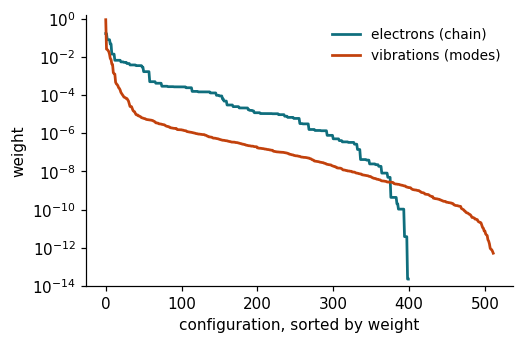

In [14]:
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.semilogy(np.sort(c0_hub**2)[::-1], c="#0f6e7d", label="electrons (chain)")
ax.semilogy(np.sort(c0_vib**2)[::-1], c="#c2410c", label="vibrations (modes)")
ax.set_ylim(1e-14, 1.5)
ax.set_xlabel("configuration, sorted by weight")
ax.set_ylabel("weight")
ax.legend()
fig.savefig(f"{ROOT}/figures/week2/weights.svg")
plt.show()

Notice how different the two are. The vibrational state puts almost all of its weight on one configuration and the rest falls away fast. The chain spreads its weight over many configurations. Keep this picture in mind, because it explains most of what happens in the next tutorial.

## Keeping a slice

The whole project rests on one function. `subspace_energy` takes `H` and a list of which configurations to keep, cuts out that smaller matrix, and returns its lowest eigenvalue.

If we keep every configuration, how far off is the answer from the exact one?

In [15]:
my_guess = None

In [16]:
err = subspace_energy(H_hub, np.arange(len(H_hub))) - E0_hub
check(my_guess, round(abs(err), 6), tol=1e-6)

Put your guess in first, then run this cell again


Keeping everything is just the full problem again. The interesting part is keeping fewer. We'll keep the first k configurations in order of exact weight, for many values of k, and see how fast the error falls.

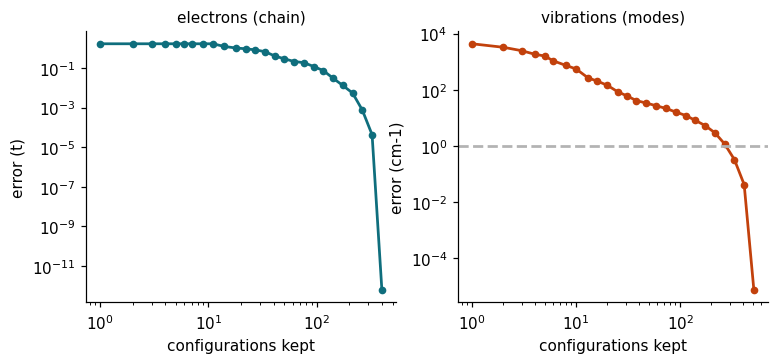

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, H, c0, E0, unit, c in [
    (axes[0], H_hub, c0_hub, E0_hub, "t", "#0f6e7d"),
    (axes[1], H_vib, c0_vib, E0_vib, "cm-1", "#c2410c"),
]:
    order = weight_order(c0)
    sizes = np.unique(np.geomspace(1, len(H) - 1, 30).astype(int))
    errs = [subspace_energy(H, order[:k]) - E0 for k in sizes]
    ax.loglog(sizes, errs, "o-", c=c)
    ax.set_xlabel("configurations kept")
    ax.set_ylabel(f"error ({unit})")

axes[1].axhline(1.0, c=(.7, .7, .7), ls="--")  # 1 cm-1, roughly spectroscopic accuracy
axes[0].set_title("electrons (chain)")
axes[1].set_title("vibrations (modes)")
fig.savefig(f"{ROOT}/figures/week2/truncation.svg")
plt.show()

Two things to notice.

First, every error is positive. Keeping fewer configurations can raise the energy but never push it below the exact answer. This is the variational principle, and it is also one of the checks in `src/test_cobweb.py`.

Second, look at the vibrations. One configuration holds 87% of the weight, yet getting within the dashed 1 cm-1 line takes a few hundred configurations. Most of the weight is easy. The last bit of accuracy lives in the long tail of tiny weights, and that tail is what makes choosing configurations hard.

## Where this leaves us

We sorted by exact weight, which needs the answer we are trying to avoid computing. On a real molecule that is not an option. The next tutorial covers the ways COBWEB chooses configurations without knowing the answer, and how they compare on these two systems.